# Distribution Transformer Monitoring

Classify the magnetic oil-gauge alarm (`MOG_A`) using temperature, oil-level,
voltage and current measurements. Compare eight classifiers using test accuracy,
classification reports and confusion matrices.

Saved model outputs are retained from the supplied run; the models have not been
retrained during this cleanup. The target, timestamp merge, 80/20 split, MinMax
scaling and model settings are unchanged. Results may vary on rerun for models
without a fixed random seed or with different library versions.

## 1. Setup

Libraries: NumPy, pandas, Matplotlib, Seaborn, scikit-learn and XGBoost.
Place `Overview.csv` and `CurrentVoltage.csv` in `data/raw/`, or change `DATA_DIR`.

```bash
pip install numpy pandas matplotlib seaborn scikit-learn xgboost
```

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

DATA_DIR = Path("data/raw")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (10, 5), "figure.dpi": 110})
pd.set_option("display.max_columns", None)

## 2. Load and combine the sensor data

| File | Measurements |
| --- | --- |
| `Overview.csv` | Oil/winding/ambient temperature indicators, oil level and alarm/trip states |
| `CurrentVoltage.csv` | Phase voltages, phase currents, line voltages and neutral current |

Join both tables on `DeviceTimeStamp`. `MOG_A` is the target; the timestamp is
excluded from the model inputs.

In [ ]:
tf = pd.read_csv(DATA_DIR / "Overview.csv")
cv = pd.read_csv(DATA_DIR / "CurrentVoltage.csv")

tf["DeviceTimeStamp"] = pd.to_datetime(tf["DeviceTimeStamp"])
cv["DeviceTimeStamp"] = pd.to_datetime(cv["DeviceTimeStamp"])

print("Overview:", tf.shape)
print("Current and voltage:", cv.shape)
transformer = pd.merge(tf, cv, on="DeviceTimeStamp")
display(transformer.head())

Overview: (20316, 8)
Current and voltage: (19352, 11)


,DeviceTimeStamp,OTI,WTI,ATI,OLI,OTI_A,OTI_T,MOG_A,VL1,VL2,VL3,IL1,IL2,IL3,VL12,VL23,VL31,INUT
0,2019-06-25 13:06:00,0.0,0.0,0.0,37.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2019-06-27 10:49:00,0.0,0.0,0.0,38.0,0.0,0.0,0.0,238.7,238.7,238.8,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2019-06-27 10:51:00,0.0,0.0,0.0,38.0,0.0,0.0,0.0,238.4,238.5,238.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2019-06-27 10:52:00,0.0,0.0,0.0,39.0,0.0,0.0,0.0,239.9,240.0,240.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2019-06-27 10:52:00,0.0,0.0,0.0,39.0,0.0,0.0,0.0,239.9,240.0,240.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 3. Explore the measurements

Inspect the temperature relationship, measurements over time and class counts.
`MOG_A` is a binary indicator, not an oil-height measurement.

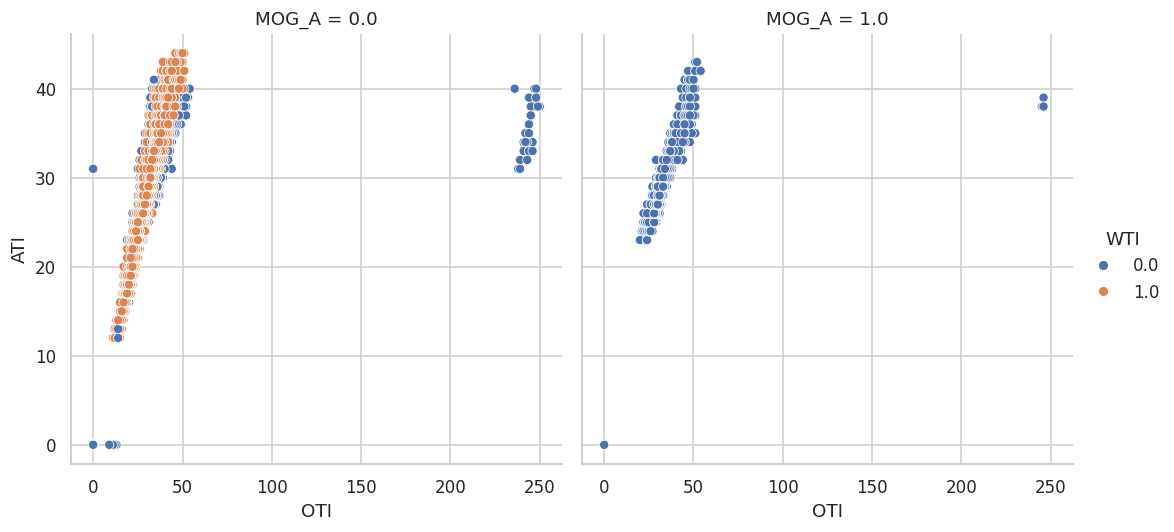

In [ ]:
sns.relplot(data=tf, x="OTI", y="ATI", hue="WTI", col="MOG_A")
plt.show()

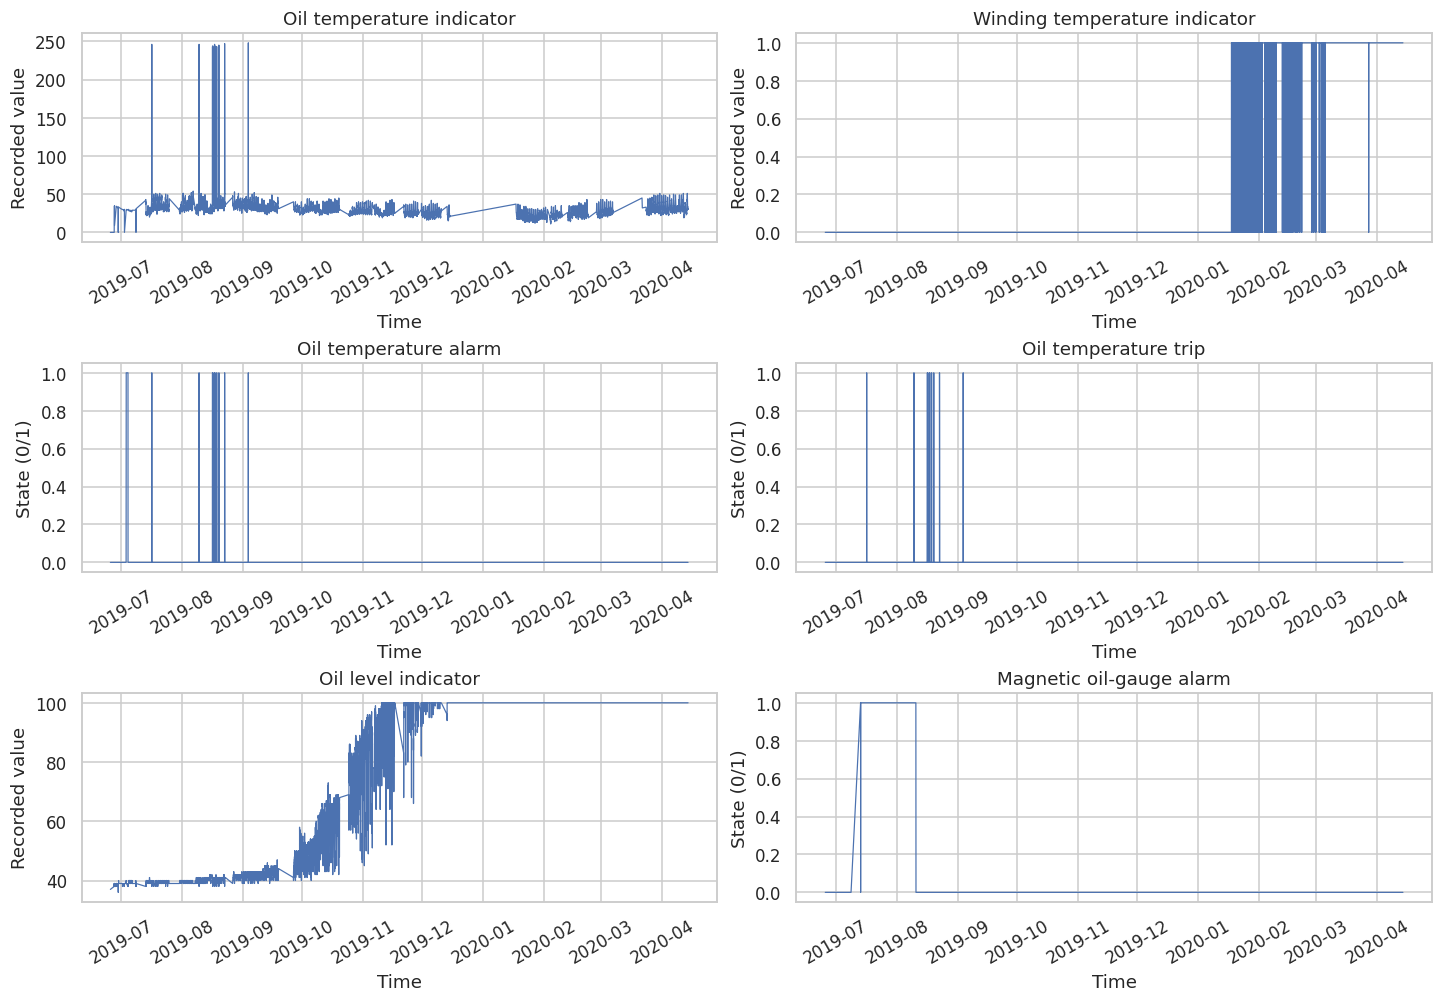

In [ ]:
channels = [
    ("OTI", "Oil temperature indicator"),
    ("WTI", "Winding temperature indicator"),
    ("OTI_A", "Oil temperature alarm"),
    ("OTI_T", "Oil temperature trip"),
    ("OLI", "Oil level indicator"),
    ("MOG_A", "Magnetic oil-gauge alarm"),
]

fig, axes = plt.subplots(3, 2, figsize=(13, 9), constrained_layout=True)
for ax, (column, title) in zip(axes.flat, channels):
    ax.plot(transformer["DeviceTimeStamp"], transformer[column], linewidth=0.8)
    ax.set(title=title, xlabel="Time", ylabel="State (0/1)" if column in {"OTI_A", "OTI_T", "MOG_A"} else "Recorded value")
    ax.tick_params(axis="x", rotation=30)
plt.show()

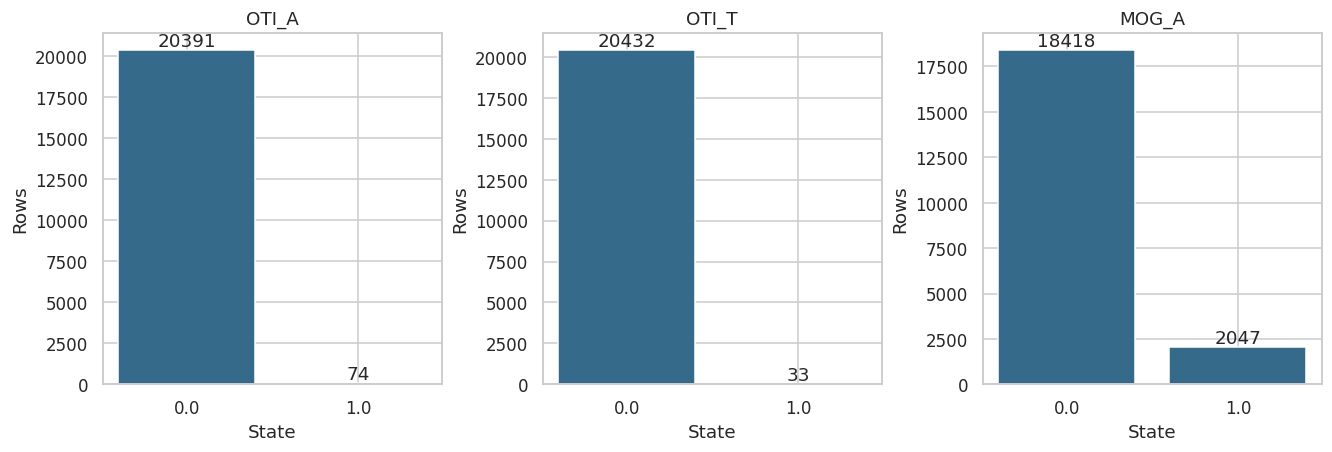

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)
for ax, column in zip(axes, ["OTI_A", "OTI_T", "MOG_A"]):
    counts = transformer[column].value_counts().sort_index()
    bars = ax.bar(counts.index.astype(str), counts.values, color="#356a8a")
    ax.bar_label(bars)
    ax.set(title=column, xlabel="State", ylabel="Rows")
plt.show()

## 4. Train–test split and scaling

Use the original random 80/20 split (`random_state=21`). Fit MinMaxScaler on the
training set, then apply the fitted transform to the test set.

In [ ]:
X = transformer.drop(['DeviceTimeStamp', 'MOG_A'], axis=1)
y = transformer['MOG_A']

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=21)

In [ ]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## 5. Fit and evaluate the classifiers

KNN uses three neighbors. Random Forest and Extra Trees each use 100 estimators.
Other model parameters use the library defaults; no hyperparameter search is performed.
The outputs below are the saved results from the supplied notebook.

### Logistic Regression

Training Accuracy    : 94.22 %
Model Accuracy Score : 94.28 %
--------------------------------------------------------
Classification_Report: 
               precision    recall  f1-score   support

         0.0       0.94      1.00      0.97      3684
         1.0       0.91      0.47      0.62       409

    accuracy                           0.94      4093
   macro avg       0.93      0.73      0.80      4093
weighted avg       0.94      0.94      0.93      4093

--------------------------------------------------------


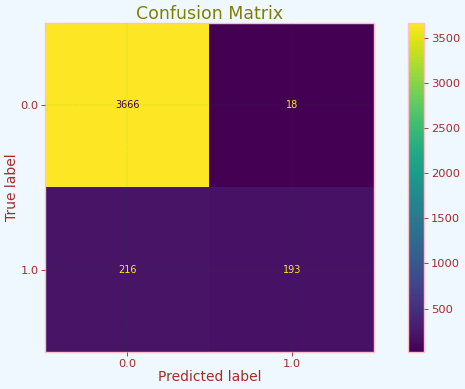

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
logreg = LogisticRegression()
logreg.fit(X_train, y_train)
y_pred_lr = logreg.predict(X_test)
log_train = round(logreg.score(X_train, y_train) * 100, 2)
log_accuracy = round(accuracy_score(y_pred_lr, y_test) * 100, 2)
print('Training Accuracy    :', log_train, '%')
print('Model Accuracy Score :', log_accuracy, '%')
print('Classification_Report: \n', classification_report(y_test, y_pred_lr))
ConfusionMatrixDisplay.from_estimator(logreg, X_test, y_test)
plt.title('Confusion Matrix')

### Support Vector Machine

Training Accuracy    : 95.41 %
Model Accuracy Score : 95.55 %
--------------------------------------------------------
Classification_Report: 
               precision    recall  f1-score   support

         0.0       0.96      0.99      0.98      3684
         1.0       0.90      0.63      0.74       409

    accuracy                           0.96      4093
   macro avg       0.93      0.81      0.86      4093
weighted avg       0.95      0.96      0.95      4093

--------------------------------------------------------


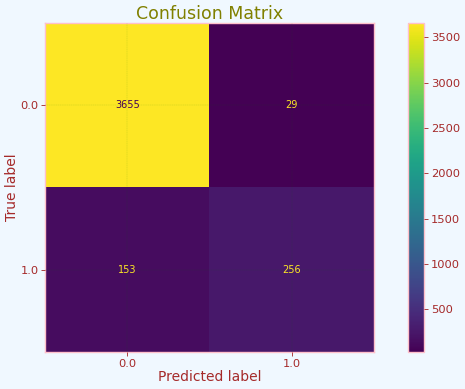

In [ ]:
from sklearn.svm import SVC
svc = SVC()
svc.fit(X_train, y_train)
y_pred_svc = svc.predict(X_test)
svc_train = round(svc.score(X_train, y_train) * 100, 2)
svc_accuracy = round(accuracy_score(y_pred_svc, y_test) * 100, 2)
print('Training Accuracy    :', svc_train, '%')
print('Model Accuracy Score :', svc_accuracy, '%')
print('Classification_Report: \n', classification_report(y_test, y_pred_svc))
ConfusionMatrixDisplay.from_estimator(svc, X_test, y_test)
plt.title('Confusion Matrix')

### K-Nearest Neighbors

Training Accuracy    : 98.08 %
Model Accuracy Score : 95.48 %
--------------------------------------------------------
Classification_Report: 
               precision    recall  f1-score   support

         0.0       0.97      0.98      0.97      3684
         1.0       0.78      0.76      0.77       409

    accuracy                           0.95      4093
   macro avg       0.88      0.87      0.87      4093
weighted avg       0.95      0.95      0.95      4093

--------------------------------------------------------


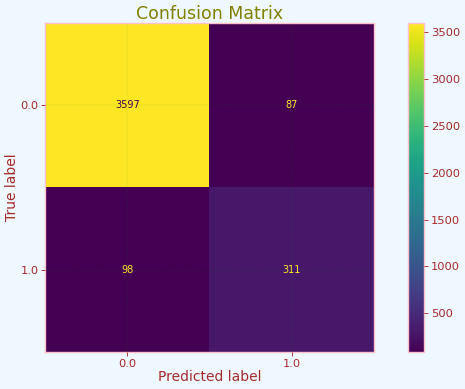

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)
knn_train = round(knn.score(X_train, y_train) * 100, 2)
knn_accuracy = round(accuracy_score(y_pred_knn, y_test) * 100, 2)
print('Training Accuracy    :', knn_train, '%')
print('Model Accuracy Score :', knn_accuracy, '%')
print('Classification_Report: \n', classification_report(y_test, y_pred_knn))
ConfusionMatrixDisplay.from_estimator(knn, X_test, y_test)
plt.title('Confusion Matrix')

### Decision Tree

Training Accuracy    : 100.0 %
Model Accuracy Score : 98.56 %
--------------------------------------------------------
Classification_Report: 
               precision    recall  f1-score   support

         0.0       0.99      0.99      0.99      3684
         1.0       0.93      0.93      0.93       409

    accuracy                           0.99      4093
   macro avg       0.96      0.96      0.96      4093
weighted avg       0.99      0.99      0.99      4093

--------------------------------------------------------


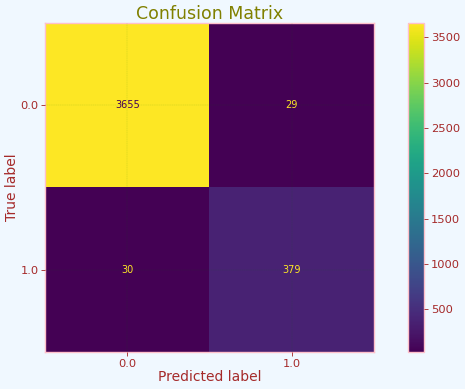

In [ ]:
from sklearn.tree import DecisionTreeClassifier
decision = DecisionTreeClassifier()
decision.fit(X_train, y_train)
y_pred_dec = decision.predict(X_test)
decision_train = round(decision.score(X_train, y_train) * 100, 2)
decision_accuracy = round(accuracy_score(y_pred_dec, y_test) * 100, 2)
print('Training Accuracy    :', decision_train, '%')
print('Model Accuracy Score :', decision_accuracy, '%')
print('Classification_Report: \n', classification_report(y_test, y_pred_dec))
ConfusionMatrixDisplay.from_estimator(decision, X_test, y_test)
plt.title('Confusion Matrix')

### Random Forest

Training Accuracy    : 100.0 %
Model Accuracy Score : 99.0 %
--------------------------------------------------------
Classification_Report: 
               precision    recall  f1-score   support

         0.0       1.00      0.99      0.99      3684
         1.0       0.94      0.96      0.95       409

    accuracy                           0.99      4093
   macro avg       0.97      0.98      0.97      4093
weighted avg       0.99      0.99      0.99      4093

--------------------------------------------------------


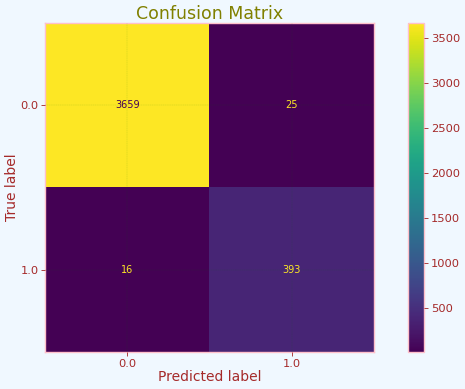

In [ ]:
from sklearn.ensemble import RandomForestClassifier
random_forest = RandomForestClassifier(n_estimators=100)
random_forest.fit(X_train, y_train)
y_pred_rf = random_forest.predict(X_test)
random_forest.score(X_train, y_train)
random_forest_train = round(random_forest.score(X_train, y_train) * 100, 2)
random_forest_accuracy = round(accuracy_score(y_pred_rf, y_test) * 100, 2)
print('Training Accuracy    :', random_forest_train, '%')
print('Model Accuracy Score :', random_forest_accuracy, '%')
print('Classification_Report: \n', classification_report(y_test, y_pred_rf))
ConfusionMatrixDisplay.from_estimator(random_forest, X_test, y_test)
plt.title('Confusion Matrix')

### Extra Trees

Training Accuracy    : 100.0 %
Model Accuracy Score : 99.02 %
--------------------------------------------------------
Classification_Report: 
               precision    recall  f1-score   support

         0.0       1.00      0.99      0.99      3684
         1.0       0.94      0.96      0.95       409

    accuracy                           0.99      4093
   macro avg       0.97      0.98      0.97      4093
weighted avg       0.99      0.99      0.99      4093

--------------------------------------------------------


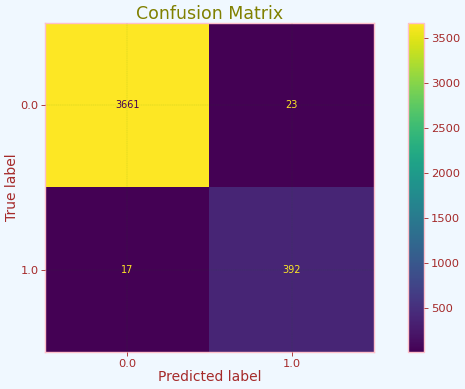

In [ ]:
from sklearn.ensemble import ExtraTreesClassifier
et = ExtraTreesClassifier(n_estimators=100)
et.fit(X_train, y_train)
y_pred_et = et.predict(X_test)
et_train = round(et.score(X_train, y_train) * 100, 2)
et_accuracy = round(accuracy_score(y_pred_et, y_test) * 100, 2)
print('Training Accuracy    :', et_train, '%')
print('Model Accuracy Score :', et_accuracy, '%')
print('Classification_Report: \n', classification_report(y_test, y_pred_et))
ConfusionMatrixDisplay.from_estimator(et, X_test, y_test)
plt.title('Confusion Matrix')

### AdaBoost

Training Accuracy    : 98.2 %
Model Accuracy Score : 97.83 %
--------------------------------------------------------
Classification_Report: 
               precision    recall  f1-score   support

         0.0       0.99      0.99      0.99      3684
         1.0       0.87      0.91      0.89       409

    accuracy                           0.98      4093
   macro avg       0.93      0.95      0.94      4093
weighted avg       0.98      0.98      0.98      4093

--------------------------------------------------------


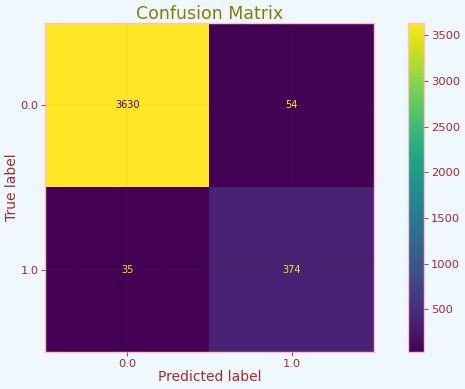

In [ ]:
from sklearn.ensemble import AdaBoostClassifier
ada = AdaBoostClassifier()
ada.fit(X_train, y_train)
y_pred_ada = ada.predict(X_test)
ada_train = round(ada.score(X_train, y_train) * 100, 2)
ada_accuracy = round(accuracy_score(y_pred_ada, y_test) * 100, 2)
print('Training Accuracy    :', ada_train, '%')
print('Model Accuracy Score :', ada_accuracy, '%')
print('Classification_Report: \n', classification_report(y_test, y_pred_ada))
ConfusionMatrixDisplay.from_estimator(ada, X_test, y_test)
plt.title('Confusion Matrix')

### XGBoost

Training Accuracy    : 100.0 %
Model Accuracy Score : 98.8 %
--------------------------------------------------------
Classification_Report: 
               precision    recall  f1-score   support

         0.0       0.99      0.99      0.99      3684
         1.0       0.94      0.94      0.94       409

    accuracy                           0.99      4093
   macro avg       0.97      0.97      0.97      4093
weighted avg       0.99      0.99      0.99      4093

--------------------------------------------------------


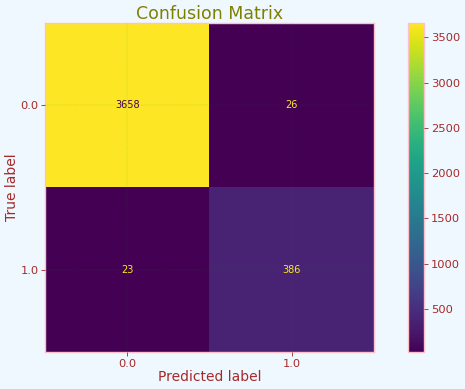

In [ ]:
import xgboost as Xgb
xgb = Xgb.XGBClassifier()
xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_test)
xgb.score(X_train, y_train)
xgb_train = round(xgb.score(X_train, y_train) * 100, 2)
xgb_accuracy = round(accuracy_score(y_pred_xgb, y_test) * 100, 2)
print('Training Accuracy    :', xgb_train, '%')
print('Model Accuracy Score :', xgb_accuracy, '%')
print('Classification_Report: \n', classification_report(y_test, y_pred_xgb))
ConfusionMatrixDisplay.from_estimator(xgb, X_test, y_test)
plt.title('Confusion Matrix')

## 6. Compare the models

The table pairs each model with its own recorded scores. Extra Trees has the highest
saved test accuracy (99.02%), followed by Random Forest (99.00%). The 0.02 percentage-point
difference describes this split; it does not establish a consistent advantage.

In [ ]:
models = pd.DataFrame([
    ("Logistic Regression", log_train, log_accuracy),
    ("Support Vector Machine", svc_train, svc_accuracy),
    ("K-Nearest Neighbors", knn_train, knn_accuracy),
    ("Decision Tree", decision_train, decision_accuracy),
    ("Random Forest", random_forest_train, random_forest_accuracy),
    ("Extra Trees", et_train, et_accuracy),
    ("AdaBoost", ada_train, ada_accuracy),
    ("XGBoost", xgb_train, xgb_accuracy),
], columns=["Model", "Training accuracy (%)", "Test accuracy (%)"])

models = models.sort_values("Test accuracy (%)", ascending=False).reset_index(drop=True)
display(models)

Model,Training accuracy (%),Test accuracy (%)
Extra Trees,100.00,99.02
Random Forest,100.00,99.00
XGBoost,100.00,98.80
Decision Tree,100.00,98.56
AdaBoost,98.20,97.83
Support Vector Machine,95.41,95.55
K-Nearest Neighbors,98.08,95.48
Logistic Regression,94.22,94.28


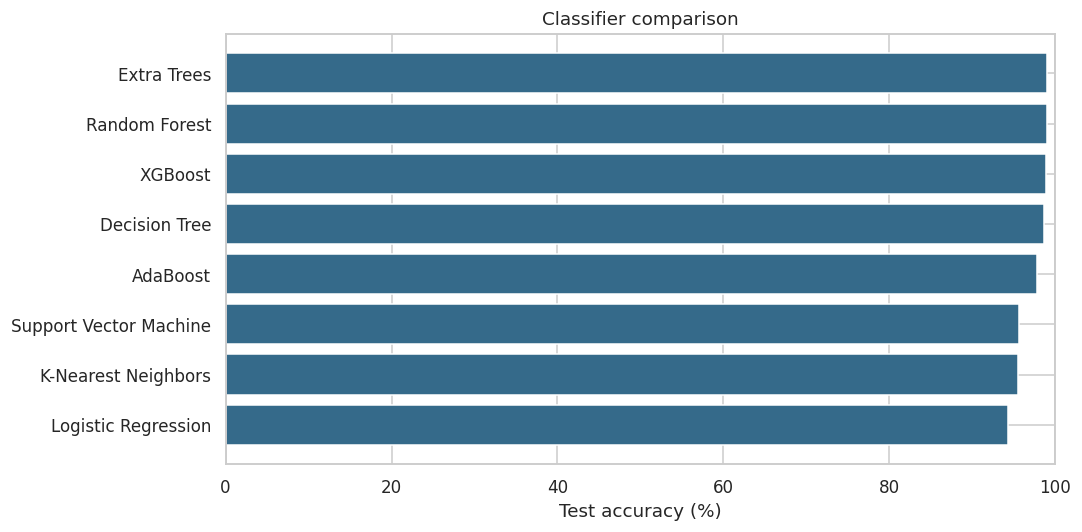

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(models["Model"], models["Test accuracy (%)"], color="#356a8a")
ax.invert_yaxis()
ax.set(xlim=(0, 100), xlabel="Test accuracy (%)", title="Classifier comparison")
plt.tight_layout()
plt.show()

## 7. Inspect Extra Trees predictions

Compare the classifier's predictions with the corresponding test labels.

In [ ]:
prediction = et.predict(X_test)
print(prediction)

[0. 0. 1. ... 1. 0. 0.]


In [ ]:
cross_checking = pd.DataFrame({"Actual": y_test, "Predicted": prediction})
display(cross_checking.head(20))

## Notes

The task is classification of the recorded oil-gauge alarm at the same timestamp.
The notebook does not calculate ROC-AUC or predict a future failure horizon.
The original timestamp merge and random split are retained; repeated timestamps
and nearby observations may make the reported test performance optimistic.

## References


- Dataset: [Distributed Transformer Monitoring by Sreshta Putchala](https://www.kaggle.com/datasets/sreshta140/ai-transformer-monitoring).
